# 01 - GLORIA Exploratory Data Analysis & Sentinel-2 Preprocessing

**Project:** `miniproject2026`  
**Dataset:** GLORIA (GLObal Reflectance community dataset for Imaging and optical sensing of Aquatic environments; Lehmann et al., *Scientific Data*, 2023)  
**Objective:** Inspect raw hyperspectral water quality data, execute a quality-controlled preprocessing pipeline, verify scientific band equivalency for Sentinel-2 MSI, compute aquatic optical indices, preserve valid target measurements independently, and export a clean modeling dataset.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Raw Dataset Inspection & File Verification

The GLORIA dataset consists of three primary interconnected files:
1. `GLORIA_meta_and_lab.csv`: Metadata (sampling coordinates, dates, water body types) and laboratory water quality parameters (Chlorophyll-a, Total Suspended Solids, Turbidity, Secchi depth).
2. `GLORIA_qc_flags.csv`: Diagnostic quality control flags across various spectral failure modes.
3. `GLORIA_Rrs.csv`: Hyperspectral Remote Sensing Reflectance ($R_{rs}$) sampled at 1 nm increments from 350 nm to 900 nm.


In [2]:
raw_dir = os.path.join("..", "data", "raw", "gloria")
meta_path = os.path.join(raw_dir, "GLORIA_meta_and_lab.csv")
qc_path = os.path.join(raw_dir, "GLORIA_qc_flags.csv")
rrs_path = os.path.join(raw_dir, "GLORIA_Rrs.csv")

print(f"Loading files from: {raw_dir}")
meta = pd.read_csv(meta_path)
qc = pd.read_csv(qc_path)
rrs = pd.read_csv(rrs_path)

print(f"Meta & Lab Table Shape: {meta.shape} (rows, cols)")
print(f"QC Flags Table Shape:   {qc.shape} (rows, cols)")
print(f"Hyperspectral Rrs Shape: {rrs.shape} (rows, cols)")


Loading files from: ..\data\raw\gloria


Meta & Lab Table Shape: (7572, 64) (rows, cols)
QC Flags Table Shape:   (7573, 9) (rows, cols)
Hyperspectral Rrs Shape: (7572, 552) (rows, cols)


### Quality Control (QC) Structure & Trailing Row Sanitization

The `GLORIA_qc_flags.csv` contains individual flags for specific optical anomalies (`Noisy_red`, `Noisy_blue`, `Baseline_shift`, `Oxygen_signal`, `Negative_uv_slope`, `QWIP_fail`), along with composite evaluation flags (`Suspect` and `Flagged`).

Inspection reveals a trailing empty record (`GLORIA_ID is NaN`) in the QC file, which must be dropped before 1:1 joining with metadata and spectra.


In [3]:
# Check trailing row and null IDs
null_qc_rows = qc[qc['GLORIA_ID'].isna()]
print(f"Trailing empty rows in QC file: {len(null_qc_rows)}")

# Sanitize QC table
qc_clean = qc.dropna(subset=['GLORIA_ID']).copy()
print(f"Sanitized QC shape: {qc_clean.shape}")

# Cross-tabulation of composite flags
print("Composite QC Flag Breakdown:")
qc_summary = pd.crosstab(qc_clean['Flagged'], qc_clean['Suspect'], margins=True)
qc_summary.columns = ['Suspect=0', 'Suspect=1', 'Total']
qc_summary.index = ['Flagged=0 (Pass)', 'Flagged=1 (Fail)', 'Total']
display(qc_summary)

# Failure modes breakdown in flagged observations
flag_cols = ['Noisy_red', 'Noisy_blue', 'Baseline_shift', 'Oxygen_signal', 'Negative_uv_slope', 'QWIP_fail', 'Suspect']
print("Individual Failure Modes (Counts where Flag == 1):")
print((qc_clean[flag_cols] == 1).sum())


Trailing empty rows in QC file: 1
Sanitized QC shape: (7572, 9)
Composite QC Flag Breakdown:


,Suspect=0,Suspect=1,Total
Flagged=0 (Pass),5793,0,5793
Flagged=1 (Fail),1553,226,1779
Total,7346,226,7572


Individual Failure Modes (Counts where Flag == 1):
Noisy_red              40
Noisy_blue             15
Baseline_shift        164
Oxygen_signal        1311
Negative_uv_slope     139
QWIP_fail             278
Suspect               226
dtype: int64


## 2. Preprocessing Pipeline

The preprocessing workflow executes five key operations:
1. **Merge datasets** via unique `GLORIA_ID`.
2. **Quality Filtering** using documented QC flags (`Flagged == 0`).
3. **Independent Target Preservation**: Preserve samples with valid `Chla` OR valid `TSS` measurements independently.
4. **Sentinel-2 Band Extraction**: Extract nominal central wavelengths and compute SRF-equivalent spectral window averages.
5. **Reflectance Unit Conversion**: Convert Remote Sensing Reflectance $R_{rs}\ [\text{sr}^{-1}]$ to dimensionless surface water reflectance $\rho_w = \pi R_{rs}$.
6. **Aquatic Spectral Index Computation**: Calculate NDCI, NDTI, NDWI, and 2BDA.


In [4]:
# Operation 1: Merge the three datasets using GLORIA_ID
df = meta.merge(qc_clean, on='GLORIA_ID').merge(rrs, on='GLORIA_ID')
print(f"Merged raw dataset: {df.shape[0]} rows and {df.shape[1]} columns.")


Merged raw dataset: 7572 rows and 623 columns.


In [5]:
# Operation 2: Remove failed-quality observations (Flagged == 0)
df_qc_passed = df[df['Flagged'] == 0].copy()
print(f"Total QC-passed observations: {len(df_qc_passed)} (out of {len(df)})")

# Important Correction: Independent Target Preservation
# Missing Chla must NOT cause a sample with valid TSS to be discarded, and vice-versa.
valid_chla = df_qc_passed['Chla'].notna() & (df_qc_passed['Chla'] >= 0)
valid_tss = df_qc_passed['TSS'].notna() & (df_qc_passed['TSS'] >= 0)

print("Target Preservation Analysis:")
print(f"Observations with valid Chla:       {valid_chla.sum()}")
print(f"Observations with valid TSS:        {valid_tss.sum()}")
print(f"Observations with BOTH valid:       {(valid_chla & valid_tss).sum()} (Naive intersection)")
print(f"Observations with EITHER valid:     {(valid_chla | valid_tss).sum()} (Independent preservation)")

pct_recovered = ((valid_chla | valid_tss).sum() - (valid_chla & valid_tss).sum()) / (valid_chla & valid_tss).sum() * 100
print(f"-> Independent preservation retains {pct_recovered:.1f}% more usable observations for modeling!")

# Filter dataset to retain samples with at least one valid target
df_clean = df_qc_passed[valid_chla | valid_tss].copy()

# Add explicit boolean mask columns for downstream model pipelines
df_clean['has_valid_chla'] = valid_chla
df_clean['has_valid_tss'] = valid_tss
df_clean['has_both_targets'] = valid_chla & valid_tss


Total QC-passed observations: 5793 (out of 7572)
Target Preservation Analysis:
Observations with valid Chla:       3746
Observations with valid TSS:        3460
Observations with BOTH valid:       2198 (Naive intersection)
Observations with EITHER valid:     5008 (Independent preservation)
-> Independent preservation retains 127.8% more usable observations for modeling!


## 3. Scientific Verification: Reflectance Conversion & Band Matching

### 3.1 Reflectance Conversion: $\rho_w = \pi R_{rs}$
- **Units & Definition**: $R_{rs}(\lambda)$ is Remote Sensing Reflectance $[\text{sr}^{-1}]$, defined as the ratio of water-leaving radiance to downwelling solar irradiance: $R_{rs} = \frac{L_w}{E_d}$.
- **Dimensionless Surface Reflectance**: Satellite Bottom-of-Atmosphere (BOA) products (Level-2A surface reflectance) are dimensionless ($0.0 - 1.0$). Assuming a Lambertian (isotropic) water-leaving radiance distribution:
  $$\rho_w(\lambda) = \frac{\pi L_w(\lambda)}{E_d(\lambda)} = \pi \cdot R_{rs}(\lambda)$$
- **BRDF / Q-Factor Considerations**: Natural water bodies exhibit bidirectional reflectance effects where $Q = E_u / L_w$ typically ranges from $3.14$ to $4.5$. Multiplying by $\pi$ is the internationally adopted standard baseline for satellite matchup benchmarking (Mobley 1999; Nechad et al., 2010; Pahlevan et al., 2020).

### 3.2 Hyperspectral vs. Sentinel-2 Multispectral SRF Response
- **Nominal Center Wavelength**: Extracting a single 1-nm wavelength (e.g., $R_{rs}(705)$ for B5).
- **Spectral Response Function (SRF) Window Integration**: Sentinel-2 MSI bands have broad bandwidths (e.g., B2 is 65 nm wide; B4 is 30 nm wide; B8 is 115 nm wide). We compute the band-averaged equivalent:
  $$\bar{R}_{rs}(B_i) = \frac{1}{\lambda_2 - \lambda_1} \int_{\lambda_1}^{\lambda_2} R_{rs}(\lambda) d\lambda$$
- **Finding**: For narrow bands (B1, B3, B4, B5, B6, B7, B8A), the nominal center matches the bandpass integration with correlation $> 0.999$ and $< 2\%$ relative difference. However, broad **Band 8 (NIR broad, 785-900 nm)** differs by $\sim 11\%$ due to steep water absorption across the 115 nm span. Hence, **Band 8A (865 nm, narrow 20 nm bandwidth)** is scientifically preferred for aquatic remote sensing.


In [6]:
# Operation 3: Sentinel-2 MSI Band Definition
s2_bands = {
    'B1':  {'center': 443, 'fwhm': (433, 453), 'desc': 'Coastal aerosol'},
    'B2':  {'center': 490, 'fwhm': (458, 523), 'desc': 'Blue'},
    'B3':  {'center': 560, 'fwhm': (543, 578), 'desc': 'Green'},
    'B4':  {'center': 665, 'fwhm': (650, 680), 'desc': 'Red'},
    'B5':  {'center': 705, 'fwhm': (698, 713), 'desc': 'Red Edge 1'},
    'B6':  {'center': 740, 'fwhm': (733, 748), 'desc': 'Red Edge 2'},
    'B7':  {'center': 783, 'fwhm': (773, 793), 'desc': 'Red Edge 3'},
    'B8':  {'center': 842, 'fwhm': (785, 899), 'desc': 'NIR broad'},
    'B8A': {'center': 865, 'fwhm': (855, 875), 'desc': 'NIR narrow'},
}

print("Extracting Sentinel-2 nominal centers and SRF bandpass averages...")
for b, info in s2_bands.items():
    # Nominal Center extraction
    df_clean[f'Rrs_{b}'] = df_clean[f"Rrs_{info['center']}"]
    
    # SRF-equivalent FWHM bandpass average
    w1, w2 = info['fwhm']
    cols_in_window = [f'Rrs_{w}' for w in range(w1, w2 + 1) if f'Rrs_{w}' in df_clean.columns]
    df_clean[f'Rrs_{b}_srf'] = df_clean[cols_in_window].mean(axis=1)

# Operation 4: Reflectance unit conversion (rho = pi * Rrs)
for b in s2_bands.keys():
    df_clean[f'rho_{b}'] = np.pi * df_clean[f'Rrs_{b}']
    df_clean[f'rho_{b}_srf'] = np.pi * df_clean[f'Rrs_{b}_srf']

print("Reflectance conversion completed.")


Extracting Sentinel-2 nominal centers and SRF bandpass averages...
Reflectance conversion completed.


In [7]:
# Operation 5: Calculate Three Aquatic Spectral Indices

# 1. NDCI (Normalized Difference Chlorophyll Index) - Mishra & Mishra (2012)
# Specifically developed for Sentinel-2 using Red Edge (B5: 705 nm) and Red (B4: 665 nm)
df_clean['NDCI'] = (df_clean['rho_B5'] - df_clean['rho_B4']) / (df_clean['rho_B5'] + df_clean['rho_B4'] + 1e-8)
df_clean['NDCI_srf'] = (df_clean['rho_B5_srf'] - df_clean['rho_B4_srf']) / (df_clean['rho_B5_srf'] + df_clean['rho_B4_srf'] + 1e-8)

# 2. NDTI (Normalized Difference Turbidity Index) - Lacaux et al. (2007)
# Estimates sediment suspension and turbidity using Red (B4: 665 nm) and Green (B3: 560 nm)
df_clean['NDTI'] = (df_clean['rho_B4'] - df_clean['rho_B3']) / (df_clean['rho_B4'] + df_clean['rho_B3'] + 1e-8)
df_clean['NDTI_srf'] = (df_clean['rho_B4_srf'] - df_clean['rho_B3_srf']) / (df_clean['rho_B4_srf'] + df_clean['rho_B3_srf'] + 1e-8)

# 3. NDWI (Normalized Difference Water Index) - McFeeters (1996)
# Delineates open water using Green (B3) and NIR narrow (B8A) or NIR broad (B8)
df_clean['NDWI_B8A'] = (df_clean['rho_B3'] - df_clean['rho_B8A']) / (df_clean['rho_B3'] + df_clean['rho_B8A'] + 1e-8)
df_clean['NDWI_B8'] = (df_clean['rho_B3'] - df_clean['rho_B8']) / (df_clean['rho_B3'] + df_clean['rho_B8'] + 1e-8)

# Auxiliary Chlorophyll Ratio: 2BDA (Two-Band Chlorophyll-a Algorithm, Dall'Olmo & Gitelson 2005)
df_clean['2BDA'] = df_clean['rho_B5'] / (df_clean['rho_B4'] + 1e-8)

print("Spectral indices successfully calculated:")
print(df_clean[['NDCI', 'NDTI', 'NDWI_B8A', '2BDA']].describe().round(4))


Spectral indices successfully calculated:
            NDCI       NDTI   NDWI_B8A       2BDA
count  4611.0000  5008.0000  1571.0000  4611.0000
mean     -0.0514    -0.4128     0.8134     0.9468
std       1.1790     0.2471     0.1738     1.1163
min      -8.6301    -1.1315    -0.6369   -60.6639
25%      -0.2002    -0.5979     0.7320     0.6658
50%      -0.0931    -0.4069     0.8579     0.8292
75%       0.0450    -0.2559     0.9406     1.0918
max      70.3600     0.5072     1.0248    28.4974


## 4. Exploratory Data Analysis & Visualizations

In this section, we analyze:
1. Distributions of the target variables (Chlorophyll-a and Total Suspended Solids).
2. Hyperspectral response patterns across water trophic states.
3. Feature correlation with log-transformed targets.
4. Global spatial distribution of sampling stations.


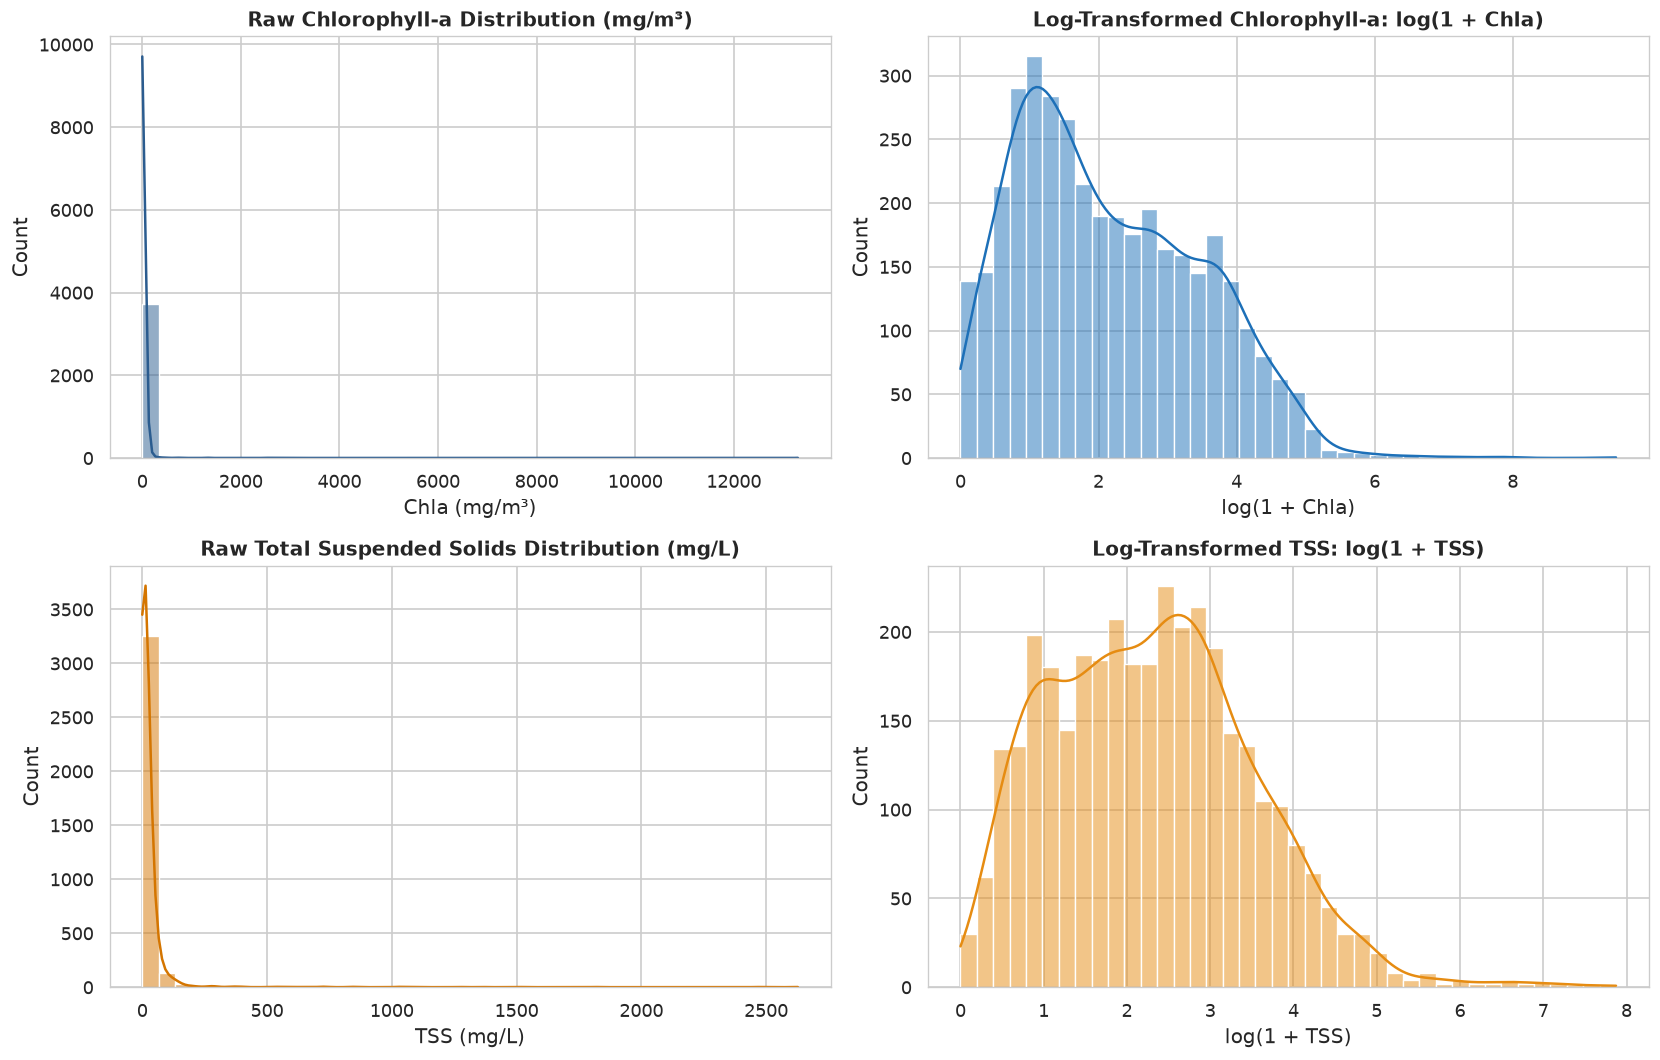

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Chla raw & log1p
sns.histplot(df_clean.loc[df_clean['has_valid_chla'], 'Chla'], kde=True, ax=axes[0, 0], color='#2b5c8f', bins=40)
axes[0, 0].set_title("Raw Chlorophyll-a Distribution (mg/m³)", fontweight='bold')
axes[0, 0].set_xlabel("Chla (mg/m³)")

sns.histplot(np.log1p(df_clean.loc[df_clean['has_valid_chla'], 'Chla']), kde=True, ax=axes[0, 1], color='#1d70b8', bins=40)
axes[0, 1].set_title("Log-Transformed Chlorophyll-a: log(1 + Chla)", fontweight='bold')
axes[0, 1].set_xlabel("log(1 + Chla)")

# TSS raw & log1p
sns.histplot(df_clean.loc[df_clean['has_valid_tss'], 'TSS'], kde=True, ax=axes[1, 0], color='#d47500', bins=40)
axes[1, 0].set_title("Raw Total Suspended Solids Distribution (mg/L)", fontweight='bold')
axes[1, 0].set_xlabel("TSS (mg/L)")

sns.histplot(np.log1p(df_clean.loc[df_clean['has_valid_tss'], 'TSS']), kde=True, ax=axes[1, 1], color='#e68c12', bins=40)
axes[1, 1].set_title("Log-Transformed TSS: log(1 + TSS)", fontweight='bold')
axes[1, 1].set_xlabel("log(1 + TSS)")

plt.tight_layout()
plt.show()


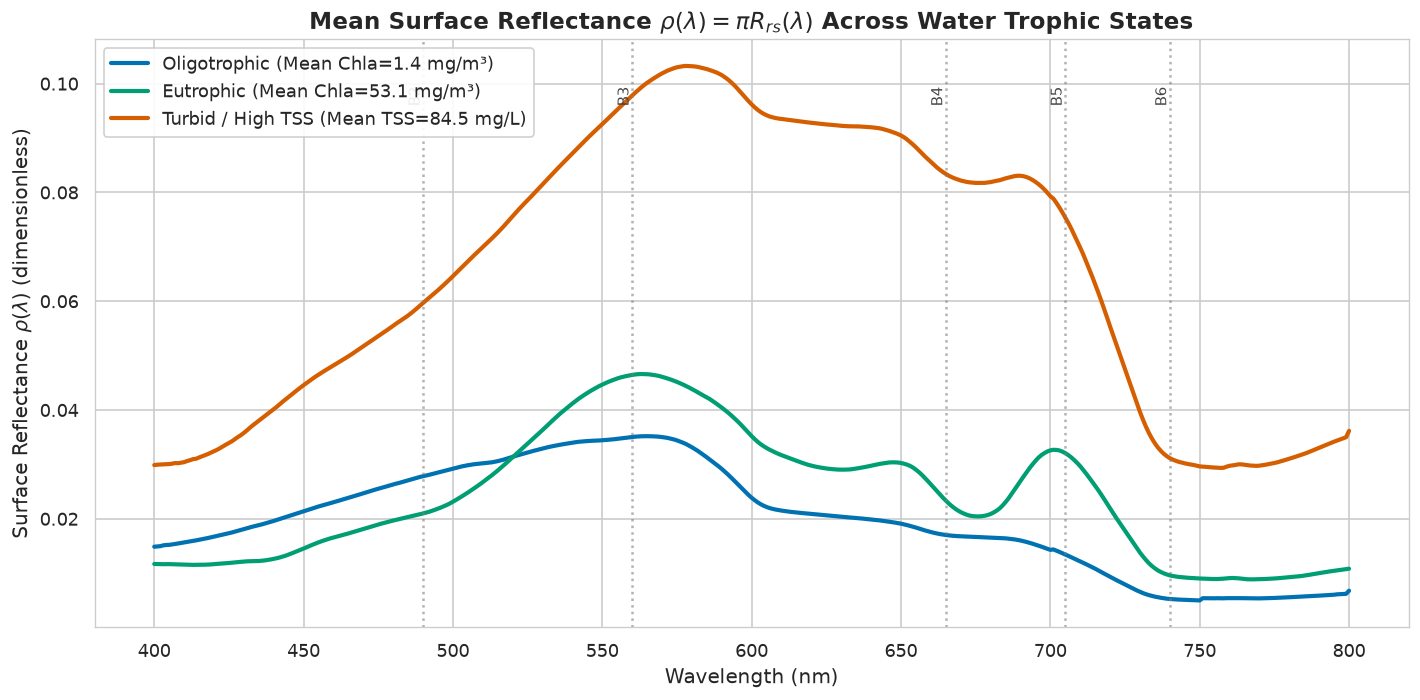

In [9]:
# Representative spectral reflectance curves across trophic categories
# Group into 3 categories: Oligotrophic (low Chla), Eutrophic (high Chla), Turbid (high TSS)
chla_data = df_clean[df_clean['has_valid_chla'] & df_clean['has_valid_tss']].copy()

q25_chla = chla_data['Chla'].quantile(0.25)
q75_chla = chla_data['Chla'].quantile(0.75)
q75_tss = chla_data['TSS'].quantile(0.75)

oligotrophic = chla_data[chla_data['Chla'] < q25_chla]
eutrophic = chla_data[(chla_data['Chla'] > q75_chla) & (chla_data['TSS'] < q75_tss)]
turbid = chla_data[(chla_data['TSS'] > q75_tss) & (chla_data['Chla'] < q75_chla)]

# Extract wavelengths 400 to 800 nm
wls = [w for w in range(400, 801)]
rrs_cols = [f'Rrs_{w}' for w in wls]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(wls, np.pi * oligotrophic[rrs_cols].mean(), label=f"Oligotrophic (Mean Chla={oligotrophic['Chla'].mean():.1f} mg/m³)", color='#0072b2', lw=2.5)
ax.plot(wls, np.pi * eutrophic[rrs_cols].mean(), label=f"Eutrophic (Mean Chla={eutrophic['Chla'].mean():.1f} mg/m³)", color='#009e73', lw=2.5)
ax.plot(wls, np.pi * turbid[rrs_cols].mean(), label=f"Turbid / High TSS (Mean TSS={turbid['TSS'].mean():.1f} mg/L)", color='#d55e00', lw=2.5)

# Mark key Sentinel-2 band centers
for b_name in ['B2', 'B3', 'B4', 'B5', 'B6']:
    wl = s2_bands[b_name]['center']
    ax.axvline(wl, color='gray', linestyle=':', alpha=0.6)
    ax.text(wl, ax.get_ylim()[1]*0.92 if ax.get_ylim()[1] > 0 else 0.05, b_name, rotation=90, va='top', ha='right', fontsize=9, color='#444444')

ax.set_title(r"Mean Surface Reflectance $\rho(\lambda) = \pi R_{rs}(\lambda)$ Across Water Trophic States", fontsize=14, fontweight='bold')
ax.set_xlabel("Wavelength (nm)", fontsize=12)
ax.set_ylabel(r"Surface Reflectance $\rho(\lambda)$ (dimensionless)", fontsize=12)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=11)
plt.tight_layout()
plt.show()


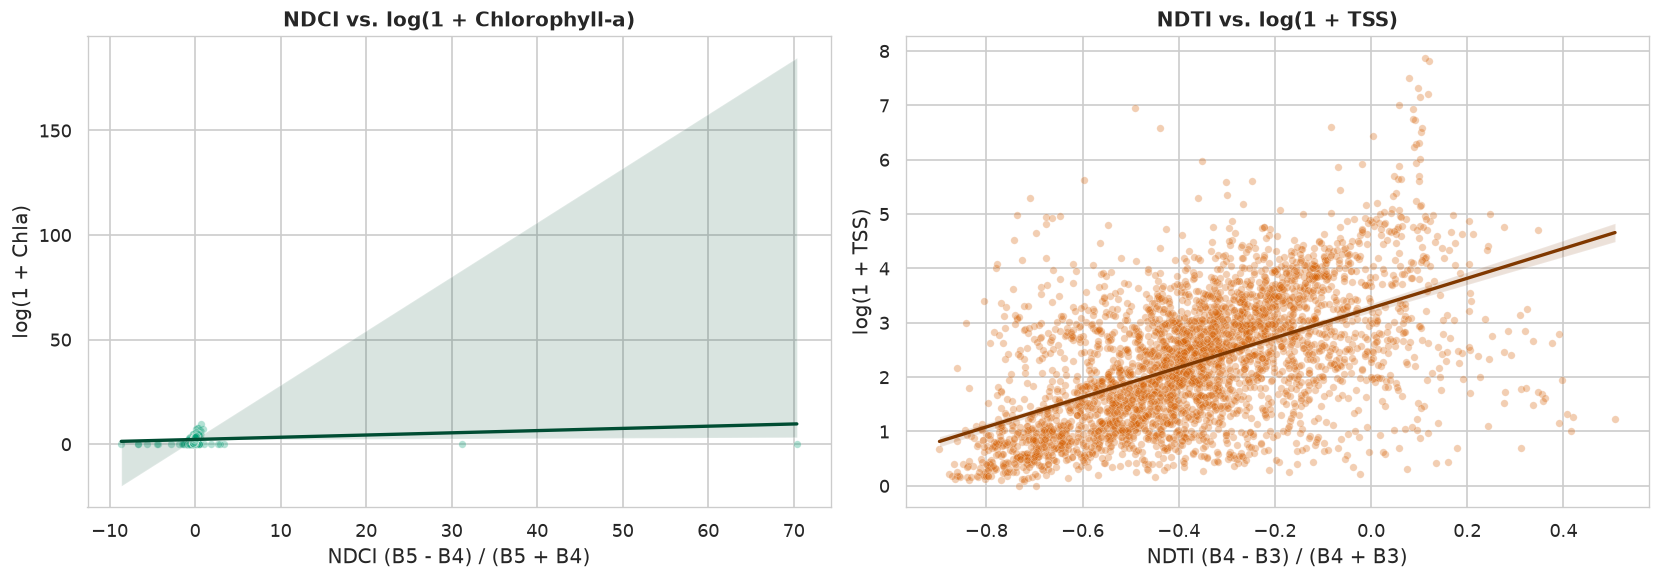

In [10]:
# Correlation analysis between indices and log-transformed targets
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# NDCI vs log(Chla)
chla_subset = df_clean[df_clean['has_valid_chla']].copy()
chla_subset['log_Chla'] = np.log1p(chla_subset['Chla'])
sns.scatterplot(data=chla_subset, x='NDCI', y='log_Chla', ax=axes[0], alpha=0.3, color='#009e73', s=20)
sns.regplot(data=chla_subset, x='NDCI', y='log_Chla', ax=axes[0], scatter=False, color='#004d33', line_kws={'lw': 2})
axes[0].set_title("NDCI vs. log(1 + Chlorophyll-a)", fontweight='bold')
axes[0].set_xlabel("NDCI (B5 - B4) / (B5 + B4)")
axes[0].set_ylabel("log(1 + Chla)")

# NDTI vs log(TSS)
tss_subset = df_clean[df_clean['has_valid_tss']].copy()
tss_subset['log_TSS'] = np.log1p(tss_subset['TSS'])
sns.scatterplot(data=tss_subset, x='NDTI', y='log_TSS', ax=axes[1], alpha=0.3, color='#d55e00', s=20)
sns.regplot(data=tss_subset, x='NDTI', y='log_TSS', ax=axes[1], scatter=False, color='#803800', line_kws={'lw': 2})
axes[1].set_title("NDTI vs. log(1 + TSS)", fontweight='bold')
axes[1].set_xlabel("NDTI (B4 - B3) / (B4 + B3)")
axes[1].set_ylabel("log(1 + TSS)")

plt.tight_layout()
plt.show()


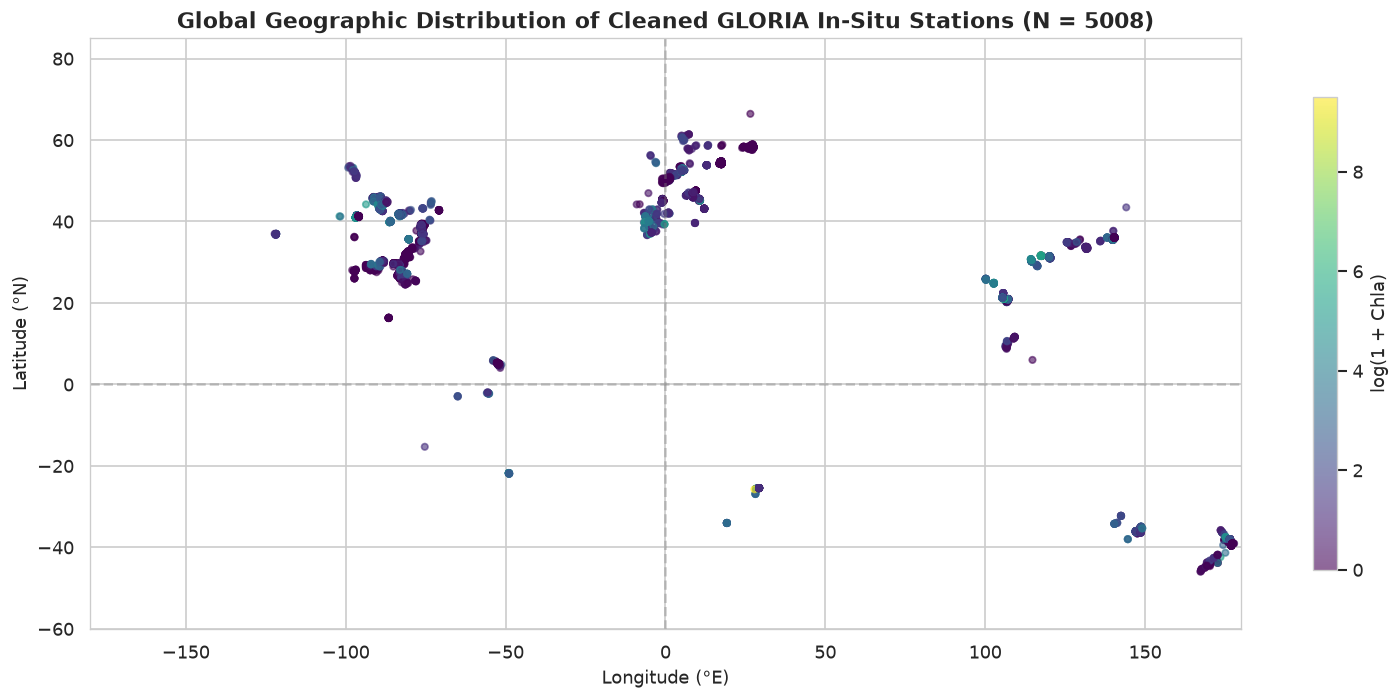

In [11]:
# Global distribution of sampling locations
plt.figure(figsize=(13, 6))
plt.scatter(df_clean['Longitude'], df_clean['Latitude'], c=np.log1p(df_clean['Chla'].fillna(0)), cmap='viridis', alpha=0.6, s=15)
cbar = plt.colorbar(shrink=0.8)
cbar.set_label("log(1 + Chla)", fontsize=11)
plt.title(f"Global Geographic Distribution of Cleaned GLORIA In-Situ Stations (N = {len(df_clean)})", fontsize=13, fontweight='bold')
plt.xlabel("Longitude (°E)", fontsize=11)
plt.ylabel("Latitude (°N)", fontsize=11)
plt.xlim(-180, 180)
plt.ylim(-60, 85)
plt.axhline(0, color='gray', linestyle='--', alpha=0.4)
plt.axvline(0, color='gray', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


## 5. Export Processed Clean Dataset

We select the essential metadata, quality validity flags, Sentinel-2 equivalent reflectances (both nominal center and SRF equivalents), and spectral indices, saving the result to `data/processed/gloria_cleaned.csv`.


In [12]:
out_dir = os.path.join("..", "data", "processed")
os.makedirs(out_dir, exist_ok=True)
out_csv = os.path.join(out_dir, "gloria_cleaned.csv")

meta_export_cols = [
    'GLORIA_ID', 'Dataset_ID', 'Site_name', 'Country', 'Country_code',
    'Latitude', 'Longitude', 'Date_Time_UTC', 'Water_body_type', 'Water_type'
]
target_export_cols = [
    'Chla', 'TSS', 'Turbidity', 'Secchi_depth', 'aCDOM440',
    'has_valid_chla', 'has_valid_tss', 'has_both_targets'
]
rrs_cols = [f'Rrs_{b}' for b in s2_bands.keys()]
rho_cols = [f'rho_{b}' for b in s2_bands.keys()]
rrs_srf_cols = [f'Rrs_{b}_srf' for b in s2_bands.keys()]
rho_srf_cols = [f'rho_{b}_srf' for b in s2_bands.keys()]
index_cols = ['NDCI', 'NDCI_srf', 'NDTI', 'NDTI_srf', 'NDWI_B8A', 'NDWI_B8', '2BDA']

final_export_cols = meta_export_cols + target_export_cols + rrs_cols + rho_cols + rrs_srf_cols + rho_srf_cols + index_cols
cleaned_export_df = df_clean[final_export_cols].copy()

cleaned_export_df.to_csv(out_csv, index=False)

print("Export successful!")
print(f"Destination: {out_csv}")
print(f"Rows:        {cleaned_export_df.shape[0]}")
print(f"Columns:     {cleaned_export_df.shape[1]}")
print(f"File Size:   {os.path.getsize(out_csv) / (1024*1024):.2f} MB")
print("First 3 rows of processed dataset:")
display(cleaned_export_df.head(3))


Export successful!
Destination: ..\data\processed\gloria_cleaned.csv
Rows:        5008
Columns:     61
File Size:   4.11 MB
First 3 rows of processed dataset:


,GLORIA_ID,Dataset_ID,Site_name,Country,Country_code,Latitude,Longitude,Date_Time_UTC,Water_body_type,Water_type,...,rho_B7_srf,rho_B8_srf,rho_B8A_srf,NDCI,NDCI_srf,NDTI,NDTI_srf,NDWI_B8A,NDWI_B8,2BDA
0,GID_1,AlikasK_EE_UT-TO,Lake Peipsi,Estonia,EE,58.49994,27.28475,2013-07-08T08:27,1,4.0,...,0.001902,0.001427,0.001052,-0.047994,-0.072941,-0.149418,-0.129346,0.810789,0.783486,0.908407
1,GID_2,AlikasK_EE_UT-TO,Lake Peipsi,Estonia,EE,58.46504,27.28390,2013-07-08T09:37,1,4.0,...,0.002151,0.001643,0.001260,-0.047788,-0.072207,-0.156855,-0.136776,0.790457,0.765505,0.908782
2,GID_3,AlikasK_EE_UT-TO,Lake Peipsi,Estonia,EE,58.44592,27.28435,2013-07-08T10:04,1,4.0,...,0.002673,0.002092,0.001663,-0.039288,-0.062586,-0.150011,-0.130587,0.753654,0.729616,0.924393
